<a href="https://colab.research.google.com/github/gmauricio-toledo/math-ML/blob/main/Tareas/Tarea-06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1> Tarea 5: Regresión y Clasificación con Machine Learning Clásico

## Precios de computadoras

El objetivo de este problema es construir un modelo para predecir el precio en dólares de computadoras portátiles basándose en sus especificaciones técnicas y componentes de hardware.

In [2]:
!gdown 1whDUO7N6ztt4bEVDakhBQOOLCWtFxo_g

Downloading...
From: https://drive.google.com/uc?id=1whDUO7N6ztt4bEVDakhBQOOLCWtFxo_g
To: /content/laptop_prices.csv
100% 972k/972k [00:00<00:00, 60.1MB/s]


In [3]:
import pandas as pd

computer_df = pd.read_csv('laptop_prices.csv')
computer_df

,Brand,Processor,RAM (GB),Storage,GPU,Screen Size (inch),Resolution,Battery Life (hours),Weight (kg),Operating System,Price ($)
0,Apple,AMD Ryzen 3,64,512GB SSD,Nvidia GTX 1650,17.3,2560x1440,8.9,1.42,FreeDOS,3997.07
1,Razer,AMD Ryzen 7,4,1TB SSD,Nvidia RTX 3080,14.0,1366x768,9.4,2.57,Linux,1355.78
2,Asus,Intel i5,32,2TB SSD,Nvidia RTX 3060,13.3,3840x2160,8.5,1.74,FreeDOS,2673.07
3,Lenovo,Intel i5,4,256GB SSD,Nvidia RTX 3080,13.3,1366x768,10.5,3.10,Windows,751.17
4,Razer,Intel i3,4,256GB SSD,AMD Radeon RX 6600,16.0,3840x2160,5.7,3.38,Linux,2059.83
...,...,...,...,...,...,...,...,...,...,...,...
11763,Acer,Intel i3,4,2TB SSD,Nvidia RTX 2060,17.3,1366x768,11.5,1.58,macOS,704.82
11764,Asus,Intel i3,4,2TB SSD,AMD Radeon RX 6800,16.0,1366x768,9.5,2.14,Linux,775.59
11765,Razer,AMD Ryzen 9,4,2TB SSD,AMD Radeon RX 6600,15.6,2560x1440,8.2,2.05,Linux,2789.46
11766,Samsung,AMD Ryzen 7,16,512GB SSD,Integrated,13.3,1920x1080,7.5,1.48,macOS,1067.13


In [4]:
#@title simplificación del dataset
import re

def clean_computer_data(df):
    df_clean = df.copy()

    # 1. Simplificar Almacenamiento (extraer capacidad en GB)
    def parse_storage(x):
        if pd.isna(x): return 0
        val = 0
        match = re.search(r'(\d+)\s*(GB|TB)', x, re.IGNORECASE)
        if match:
            amount = int(match.group(1))
            unit = match.group(2).upper()
            val = amount * 1024 if unit == 'TB' else amount
        return val

    df_clean['Storage_GB'] = df_clean['Storage'].apply(parse_storage)
    df_clean['Is_SSD'] = df_clean['Storage'].str.contains('SSD', case=False, na=False).astype(int)

    # 2. Simplificar GPU (Nvidia, AMD, Intel, Integrated)
    def simplify_gpu(x):
        if pd.isna(x): return 'Other'
        x_lower = x.lower()
        if 'nvidia' in x_lower: return 'Nvidia'
        elif 'amd' in x_lower or 'radeon' in x_lower: return 'AMD'
        elif 'intel' in x_lower: return 'Intel'
        elif 'integrated' in x_lower: return 'Integrated'
        return 'Other'

    df_clean['GPU_Brand'] = df_clean['GPU'].apply(simplify_gpu)

    # 3. Procesar Resolución de pantalla (calcular número total de píxeles)
    def parse_resolution(x):
        if pd.isna(x): return 0
        match = re.search(r'(\d+)\\s*x\\s*(\d+)', str(x), re.IGNORECASE)
        if match:
            return int(match.group(1)) * int(match.group(2))
        return 1920 * 1080 # valor por defecto si falla

    df_clean['Total_Pixels'] = df_clean['Resolution'].apply(parse_resolution)

    # Eliminar columnas originales que ya procesamos
    cols_to_drop = ['Storage', 'GPU', 'Resolution']
    df_clean = df_clean.drop(columns=cols_to_drop)

    return df_clean

computer_df = clean_computer_data(computer_df)
computer_df

,Brand,Processor,RAM (GB),Screen Size (inch),Battery Life (hours),Weight (kg),Operating System,Price ($),Storage_GB,Is_SSD,GPU_Brand,Total_Pixels
0,Apple,AMD Ryzen 3,64,17.3,8.9,1.42,FreeDOS,3997.07,512,1,Nvidia,2073600
1,Razer,AMD Ryzen 7,4,14.0,9.4,2.57,Linux,1355.78,1024,1,Nvidia,2073600
2,Asus,Intel i5,32,13.3,8.5,1.74,FreeDOS,2673.07,2048,1,Nvidia,2073600
3,Lenovo,Intel i5,4,13.3,10.5,3.10,Windows,751.17,256,1,Nvidia,2073600
4,Razer,Intel i3,4,16.0,5.7,3.38,Linux,2059.83,256,1,AMD,2073600
...,...,...,...,...,...,...,...,...,...,...,...,...
11763,Acer,Intel i3,4,17.3,11.5,1.58,macOS,704.82,2048,1,Nvidia,2073600
11764,Asus,Intel i3,4,16.0,9.5,2.14,Linux,775.59,2048,1,AMD,2073600
11765,Razer,AMD Ryzen 9,4,15.6,8.2,2.05,Linux,2789.46,2048,1,AMD,2073600
11766,Samsung,AMD Ryzen 7,16,13.3,7.5,1.48,macOS,1067.13,512,1,Integrated,2073600


In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

# Separar datos en conjunto de entrenamiento y prueba
X = computer_df.drop(columns=['Price ($)'])
y = computer_df['Price ($)']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=67
)

# Definir y evaluar modelo para regresión
dummy_reg = DummyRegressor(strategy='median')
dummy_reg.fit(X_train, y_train)

y_pred_dummy = dummy_reg.predict(X_test)
baseline_mae = mean_absolute_error(y_test, y_pred_dummy)

print(f"MAE del Baseline: {baseline_mae:.2f}")

MAE del Baseline: 909.19


**Analisis EDA**

Brand                   0
Processor               0
RAM (GB)                0
Screen Size (inch)      0
Battery Life (hours)    0
Weight (kg)             0
Operating System        0
Storage_GB              0
Is_SSD                  0
GPU_Brand               0
Total_Pixels            0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
Index: 8826 entries, 3719 to 11075
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Brand                 8826 non-null   object 
 1   Processor             8826 non-null   object 
 2   RAM (GB)              8826 non-null   int64  
 3   Screen Size (inch)    8826 non-null   float64
 4   Battery Life (hours)  8826 non-null   float64
 5   Weight (kg)           8826 non-null   float64
 6   Operating System      8826 non-null   object 
 7   Storage_GB            8826 non-null   int64  
 8   Is_SSD                8826 non-null   int64  
 9   GPU_Brand             8826 no

,RAM (GB),Screen Size (inch),Battery Life (hours),Weight (kg),Storage_GB,Is_SSD,Total_Pixels
count,8826.000000,8826.000000,8826.000000,8826.000000,8826.000000,8826.000000,8826.0
mean,24.895536,15.219918,8.048300,2.340443,986.293225,0.805235,2073600.0
std,21.792474,1.436544,2.295968,0.668056,620.871797,0.396042,0.0
min,4.000000,13.300000,4.000000,1.200000,256.000000,0.000000,2073600.0
25%,8.000000,14.000000,6.100000,1.750000,512.000000,1.000000,2073600.0
50%,16.000000,15.600000,8.100000,2.350000,1024.000000,1.000000,2073600.0
75%,32.000000,16.000000,10.000000,2.910000,1024.000000,1.000000,2073600.0
max,64.000000,17.300000,12.000000,3.500000,2048.000000,1.000000,2073600.0


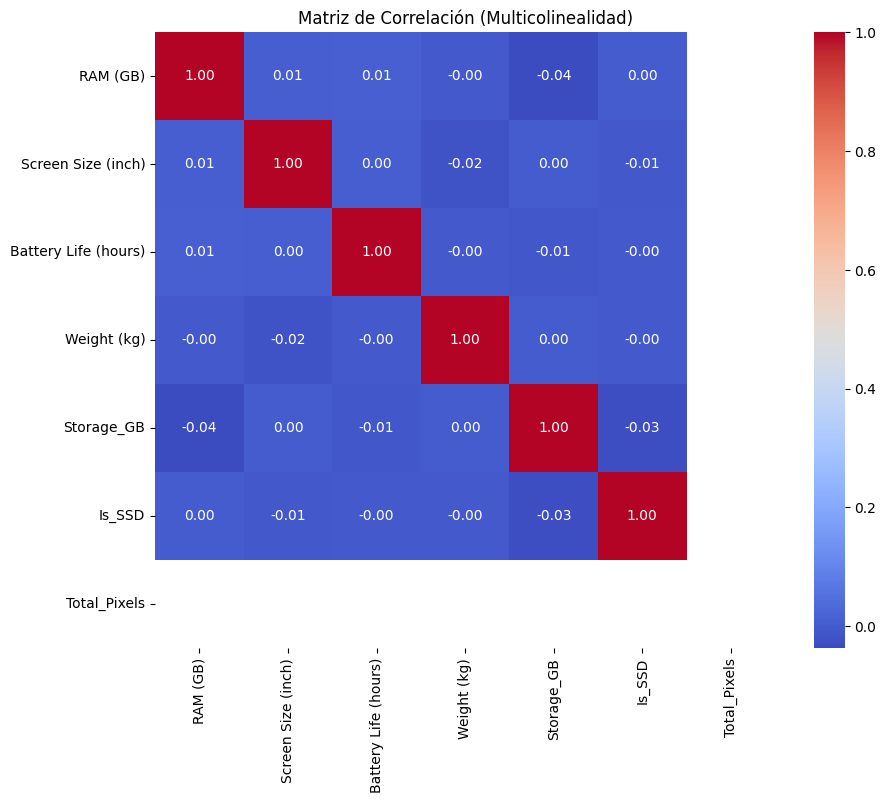

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Revisar valores faltantes
print(X_train.isnull().sum())

# Revisar tipos de variables
X_train.info()

#Estadistica descriptiva
display(X_train.describe())

# Revisar posibles problemas de multicolinealidad
# Se aíslan solo las variables numéricas para el cálculo de Pearson
num_cols_eda = X_train.select_dtypes(include=['int64', 'float64']).columns

plt.figure(figsize=(10, 8))
sns.heatmap(X_train[num_cols_eda].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriz de Correlación (Multicolinealidad)")
plt.show()


**Preprocesamiento y Feature Engineering**

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_regression

# Separamos las columnas
cat_cols = ['Brand', 'Processor', 'Operating System', 'GPU_Brand']
num_cols = ['RAM (GB)', 'Screen Size (inch)', 'Battery Life (hours)',
            'Weight (kg)', 'Storage_GB', 'Is_SSD', 'Total_Pixels']

# Transformaciones para variables numéricas
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Transformaciones para variables categóricas
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
])

# Preprocesador
preprocessor = ColumnTransformer([
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

# Pipeline y reduccion a la dimensionalidad
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('selector', SelectKBest(score_func=f_regression)),
    ('model', 'passthrough')
])

**Experimentación Exhaustiva y Pipelines**

In [8]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.model_selection import RandomizedSearchCV

# Probar tres algoritmos distintos y búsqueda de hiperparámetros
param_grid = [
    {
        'model': [Ridge(random_state=67)],
        'selector__k': [5, 8, 'all'],
        'model__alpha': [0.1, 1.0, 10.0] #nivel de penalizacion en una regresión
    },
    {
        'model': [RandomForestRegressor(random_state=67)],
        'selector__k': [5, 8, 'all'],
        'model__n_estimators': [50, 100],
        'model__max_depth': [None, 10, 20] #límite de profundidad o crecimiento de los árboles de decisión
    },
    {
        'model': [SVR()],
        'selector__k': [5, 8, 'all'],
        'model__C': [1.0, 10.0, 100.0],
        'model__kernel': ['linear', 'rbf'] # Es la tolerancia al error
    }
]

# Búsqueda aleatoria
search = RandomizedSearchCV(
    pipeline, param_distributions=param_grid, n_iter=15,
    cv=5, scoring='neg_mean_absolute_error', random_state=67, n_jobs=-1
)

search.fit(X_train, y_train)

# Mostrar resultados
print("Mejores hiperparámetros encontrados:")
for param, value in search.best_params_.items():
    print(f"{param}: {value}")

print(f"\nMAE en validación cruzada: {-search.best_score_:.2f}")

Mejores hiperparámetros encontrados:
selector__k: all
model__n_estimators: 100
model__max_depth: 10
model: RandomForestRegressor(random_state=67)

MAE en validación cruzada: 524.03


MAE del Modelo Final en Prueba: 514.67


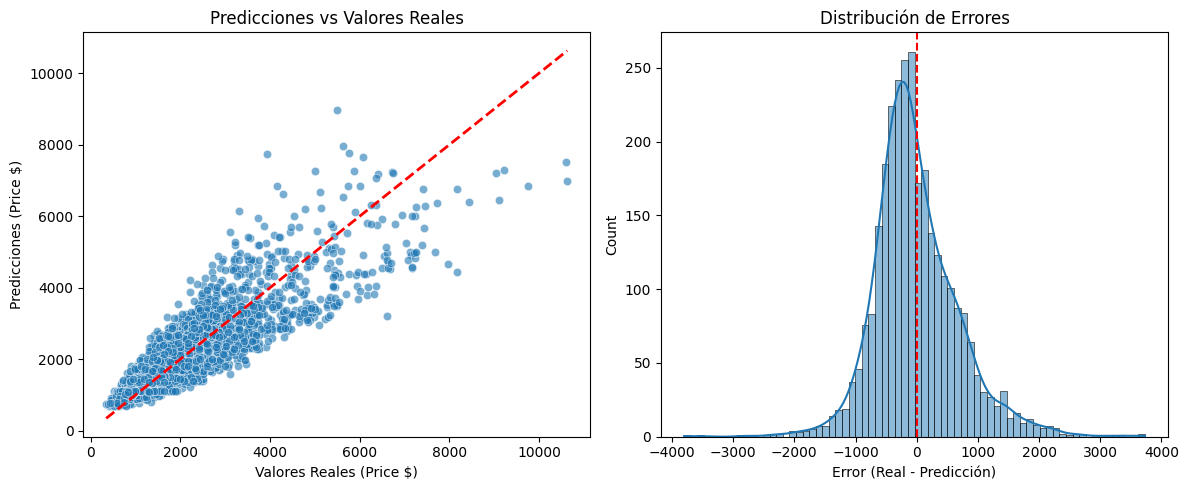

In [9]:
# Evaluación final s
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)

mae_final = mean_absolute_error(y_test, y_pred)
print(f"MAE del Modelo Final en Prueba: {mae_final:.2f}")

# Análisis gráfico de errores para tareas de regresión
errores = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico 1: Predicciones vs Valores Reales
sns.scatterplot(x=y_test, y=y_pred, ax=axes[0], alpha=0.6)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', linewidth=2)
axes[0].set_xlabel('Valores Reales (Price $)')
axes[0].set_ylabel('Predicciones (Price $)')
axes[0].set_title('Predicciones vs Valores Reales')

# Gráfico 2: Histograma de Errores (Residuos)
sns.histplot(errores, kde=True, ax=axes[1])
axes[1].axvline(x=0, color='r', linestyle='--')
axes[1].set_xlabel('Error (Real - Predicción)')
axes[1].set_title('Distribución de Errores')

plt.tight_layout()
plt.show()

Varios algoritmos de ML tienen el atributo `feature_importance_` que cuantifica que tan importante es cada variable en la predicción de la variable target. Tiene shape `(n_features,)`. La interpretación de este valor depende del algoritmo y depende fuertemente del preprocesamiento de las features.

**No todos los algortmos tienen este atributo**

🔴 Averigua 3 algoritmos que sí tienen el atributo y 3 que no. Escríbelos abajo.

In [10]:
importancias = best_model.named_steps['model'].feature_importances_
print(importancias.shape)

importancias

(32,)


array([0.4602677 , 0.01739836, 0.02910654, 0.02872719, 0.0105044 ,
       0.01118345, 0.        , 0.00056584, 0.05885487, 0.00073438,
       0.00071156, 0.00061826, 0.00085552, 0.02429184, 0.00058284,
       0.03768122, 0.00080528, 0.00622723, 0.00055331, 0.017134  ,
       0.09647008, 0.00736265, 0.00134125, 0.01614747, 0.09723956,
       0.00322639, 0.00337562, 0.00367483, 0.00357526, 0.00213129,
       0.05648357, 0.00216823])

A continuación cuantificamos la importancia de cada variable en este problema en particular. En este caso, no coincide el tamaño del arreglo `feature_importance` con el tamaño del dataset

In [11]:
print(f"Número de variables en el dataset: {computer_df.shape[1]}")
print(f"Número de variables en el feature_importance: {importancias.shape[0]}")

Número de variables en el dataset: 12
Número de variables en el feature_importance: 32


Esto ocurre porque las variables categóricas las convertimos en numéricamos por medio del one-hot enconding, lo que añadió variables.

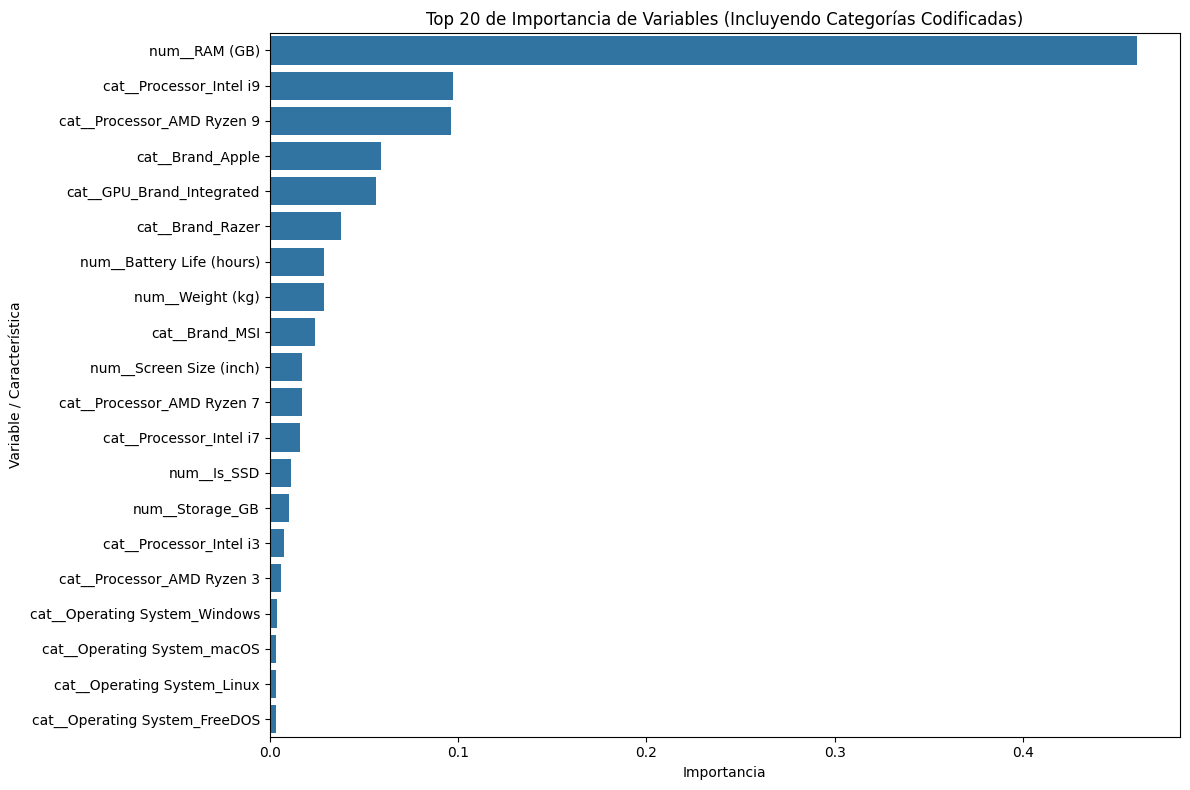

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Obtener los nombres de las columnas transformadas del preprocesador
preprocessor_step = best_model.named_steps['preprocessor']
feature_names = preprocessor_step.get_feature_names_out()

# 2. Obtener las importancias de las variables del modelo entrenado
importancias = best_model.named_steps['model'].feature_importances_

# 3. Crear el DataFrame con los nombres de características transformadas
importancias_df = pd.DataFrame({
    'Variable': feature_names,
    'Importancia': importancias
})

# 4. Ordenar y mostrar las variables más importantes
importancias_df = importancias_df.sort_values(by='Importancia', ascending=False)

# Graficar
plt.figure(figsize=(12, 8))
sns.barplot(x='Importancia', y='Variable', data=importancias_df.head(20))
plt.title('Top 20 de Importancia de Variables (Incluyendo Categorías Codificadas)')
plt.xlabel('Importancia')
plt.ylabel('Variable / Característica')
plt.tight_layout()
plt.show()

🔴 De los ejercicios de la tarea anterior, escoger uno de los ejercicios comunes y el único. En cada uno de ellos, extraer la importancia de las variables usando algún método apropiado. Graficar la importancia (puedes basarte en la celda anterior) en cada uno de los dos casos.